# CNN-Based Weapon-in-Hand Detection System for School CCTV
Classes: harmless_object, melee, ranged, student

**C1: Baseline (Optimizer: Adam)**

3 Conv2D (32, 64, 128) + 3 MaxPooling2D, Dense 128, relu / softmax, 150x150, batch 32, 4 epochs, adam

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
# Construct an instance of ImageDataGenerator class
# rescale = 1./255 normalizes the pixel values from 0-255 to 0-1
train_datagen = ImageDataGenerator(rescale = 1./255)
test_datagen = ImageDataGenerator(rescale = 1./255)

In [3]:
# Use flow_from_directory to take the path and generate batches of data
train_iterator = train_datagen.flow_from_directory(
    'dataset/train',
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical'
)

test_iterator = test_datagen.flow_from_directory(
    'dataset/test',
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical'
)

Found 15803 images belonging to 4 classes.
Found 880 images belonging to 4 classes.


In [4]:
# Defining the sequential model for weapon-in-hand classification
model = keras.Sequential()

# Convolution and Pooling Layers
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

# Core Layers
model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))

# Output layer: 4 nodes with softmax (harmless_object, melee, ranged, student)
model.add(layers.Dense(4, activation='softmax'))

D:\Eztel71\Documents\Projects\Weapons_CNN\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
# Compile and fit the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

history = model.fit(train_iterator, validation_data=test_iterator, epochs=4)

Epoch 1/4
494/494 ━━━━━━━━━━━━━━━━━━━━ 97s 194ms/step - accuracy: 0.4848 - loss: 1.1483 - val_accuracy: 0.6170 - val_loss: 0.9780
Epoch 2/4
494/494 ━━━━━━━━━━━━━━━━━━━━ 94s 189ms/step - accuracy: 0.6360 - loss: 0.8788 - val_accuracy: 0.6693 - val_loss: 0.8507
Epoch 3/4
494/494 ━━━━━━━━━━━━━━━━━━━━ 85s 172ms/step - accuracy: 0.7574 - loss: 0.6046 - val_accuracy: 0.6307 - val_loss: 0.9888
Epoch 4/4
494/494 ━━━━━━━━━━━━━━━━━━━━ 88s 177ms/step - accuracy: 0.8830 - loss: 0.3162 - val_accuracy: 0.6534 - val_loss: 1.1045


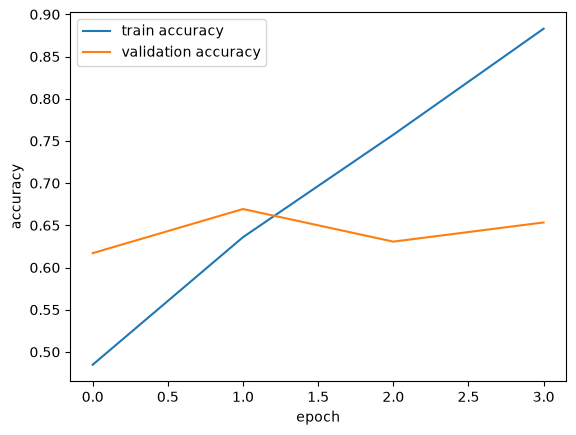

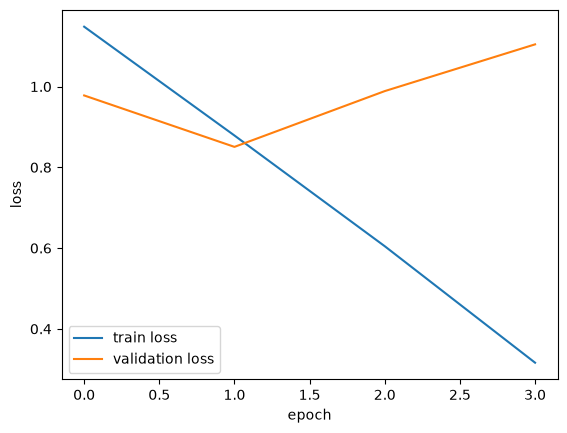

In [6]:
# Plot training vs validation accuracy and loss per epoch
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

In [7]:
# Evaluating the Model using test data
model.evaluate(test_iterator)

28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - accuracy: 0.6534 - loss: 1.1045


[1.1045441627502441, 0.6534090638160706]

In [8]:
# Saving Model
model.save('WeaponCNN_C1.h5')

In [9]:
# get the class labels from iterator
labels = train_iterator.class_indices
print(labels)

{'harmless_object': 0, 'melee': 1, 'ranged': 2, 'student': 3}


## Prediction

In [10]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt
import numpy as np

In [11]:
# load the saved model
model = load_model('WeaponCNN_C1.h5')

# class labels from the iterator
labels = ['harmless_object', 'melee', 'ranged', 'student']

# TYPICAL PHOTOS TEST
Photos from `dataset/test/` in the most common style of each class (not used in training)

## student_0035.jpg
Actual: student

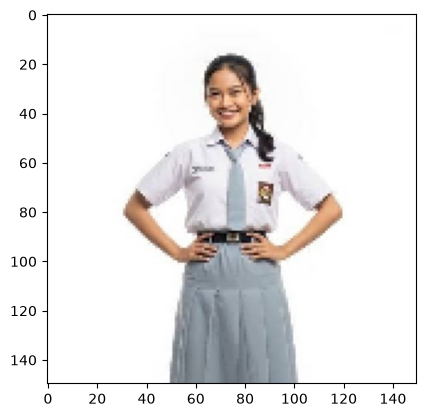

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
[[0.62341744 0.07782324 0.01408104 0.28467834]]
harmless_object


In [12]:
# load an image for prediction
img = load_img('dataset/test/student/student_0035.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## student_0232.jpg
Actual: student

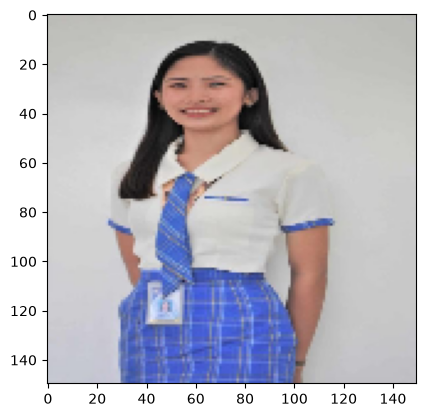

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
[[4.2073545e-04 4.3896257e-06 2.2103952e-05 9.9955279e-01]]
student


In [13]:
# load an image for prediction
img = load_img('dataset/test/student/student_0232.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_0302.jpg
Actual: harmless_object

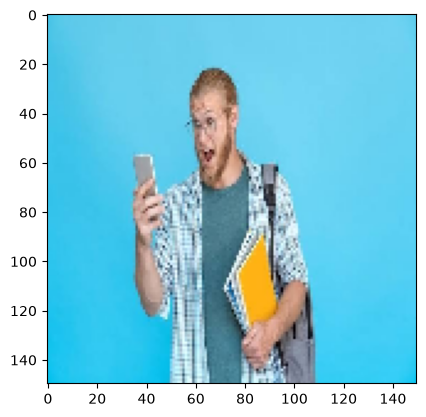

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
[[0.14148906 0.26093972 0.08754825 0.51002294]]
student


In [14]:
# load an image for prediction
img = load_img('dataset/test/harmless_object/harmless_object_0302.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_0321.jpg
Actual: harmless_object

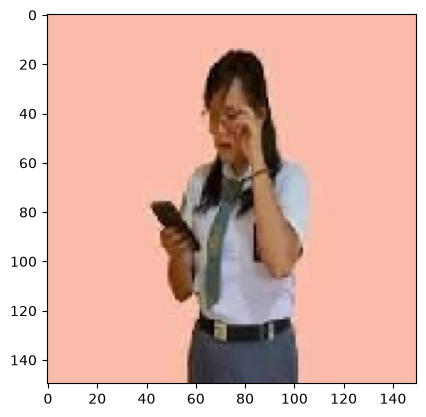

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
[[1.8905473e-01 1.2574545e-03 9.6932221e-05 8.0959094e-01]]
student


In [15]:
# load an image for prediction
img = load_img('dataset/test/harmless_object/harmless_object_0321.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_0107.jpg
Actual: melee

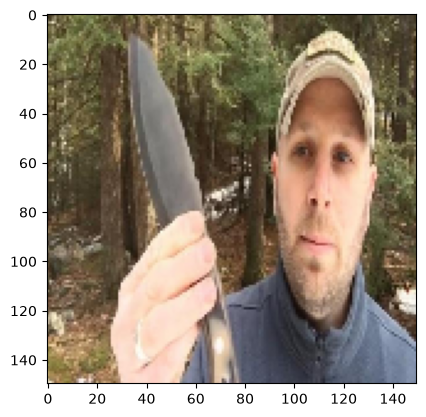

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[6.175014e-04 9.987509e-01 5.862840e-04 4.528182e-05]]
melee
ALERT: melee weapon detected, confidence 0.9987509


In [16]:
# load an image for prediction
img = load_img('dataset/test/melee/melee_0107.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_0155.jpg
Actual: melee

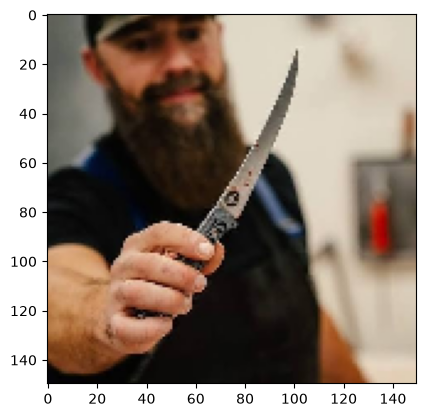

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
[[1.5251378e-02 9.8376298e-01 9.8521775e-04 4.4660172e-07]]
melee
ALERT: melee weapon detected, confidence 0.983763


In [17]:
# load an image for prediction
img = load_img('dataset/test/melee/melee_0155.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_0103.jpg
Actual: ranged

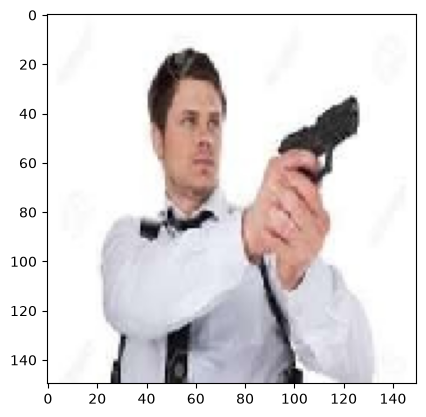

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
[[0.05420611 0.00345448 0.4623909  0.4799485 ]]
student


In [18]:
# load an image for prediction
img = load_img('dataset/test/ranged/ranged_0103.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_0139.jpg
Actual: ranged

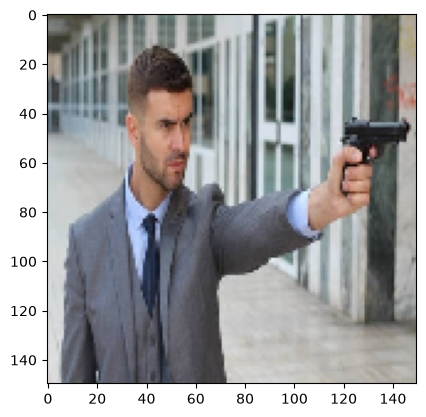

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
[[0.373125   0.01123153 0.30736893 0.30827457]]
harmless_object


In [19]:
# load an image for prediction
img = load_img('dataset/test/ranged/ranged_0139.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

# OUR PHOTOS TEST
Our own photos from `my_photos_test/` (not used in training)

## student_test1.jpg
Actual: student

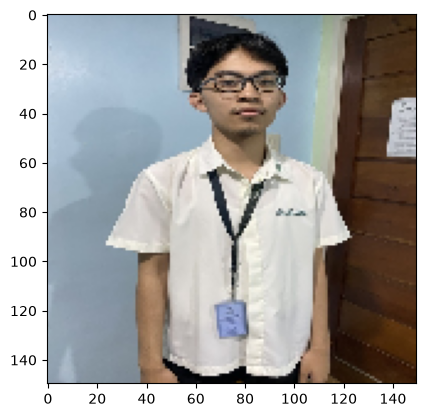

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
[[8.2510620e-02 6.9825965e-01 1.8097264e-04 2.1904875e-01]]
melee
ALERT: melee weapon detected, confidence 0.69825965


In [20]:
# load an image for prediction
img = load_img('my_photos_test/student_test1.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## student_test2.jpg
Actual: student

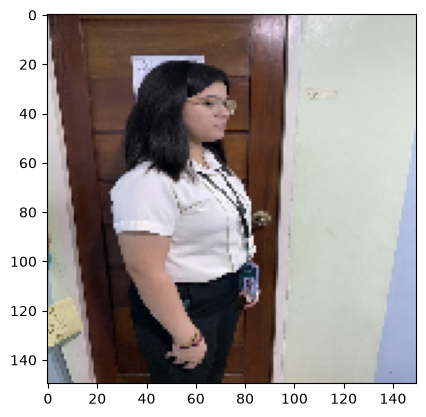

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
[[3.2279247e-01 2.1846414e-02 9.9500867e-05 6.5526164e-01]]
student


In [21]:
# load an image for prediction
img = load_img('my_photos_test/student_test2.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_test1.jpg
Actual: harmless_object

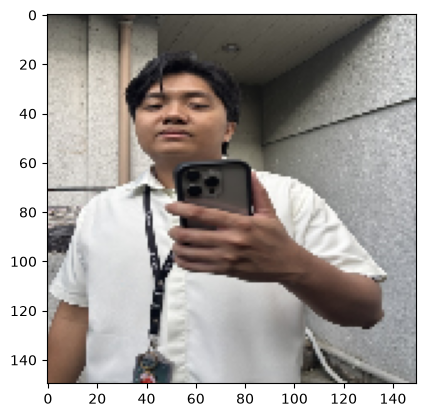

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
[[0.8170823  0.11960987 0.02654185 0.03676595]]
harmless_object


In [22]:
# load an image for prediction
img = load_img('my_photos_test/harmless_object_test1.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_test2.jpg
Actual: harmless_object

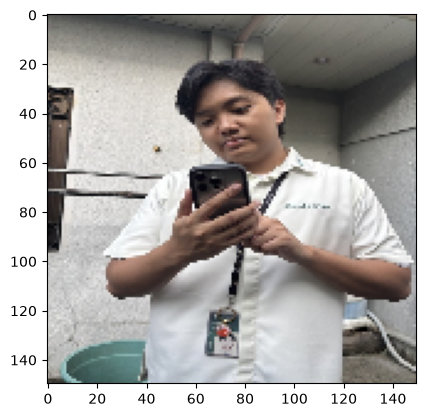

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
[[9.8924166e-01 1.0357163e-02 2.7018489e-04 1.3104145e-04]]
harmless_object


In [23]:
# load an image for prediction
img = load_img('my_photos_test/harmless_object_test2.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_test1.jpg
Actual: melee

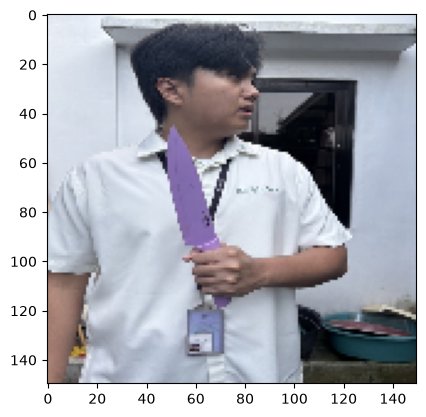

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
[[4.7575729e-04 1.3384765e-02 7.4293101e-05 9.8606527e-01]]
student


In [24]:
# load an image for prediction
img = load_img('my_photos_test/melee_test1.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_test2.jpg
Actual: melee

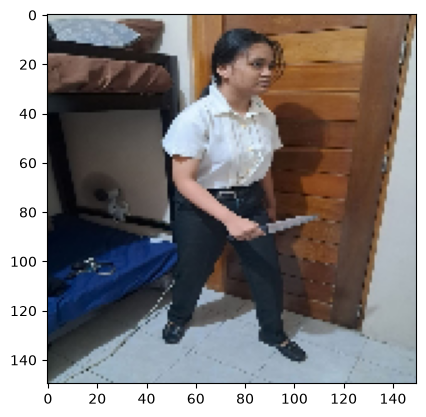

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[0.04551778 0.46626794 0.00536222 0.48285198]]
student


In [25]:
# load an image for prediction
img = load_img('my_photos_test/melee_test2.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_test1.jpg
Actual: ranged

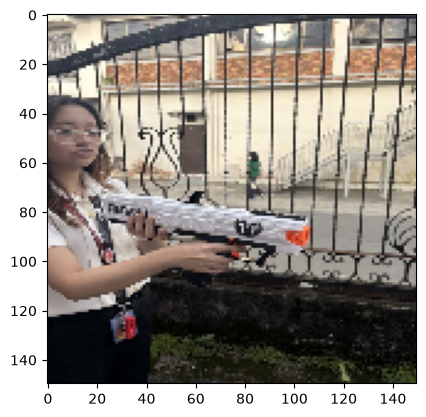

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
[[0.02304632 0.18997158 0.7719606  0.01502148]]
ranged
ALERT: ranged weapon detected, confidence 0.7719606


In [26]:
# load an image for prediction
img = load_img('my_photos_test/ranged_test1.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_test2.jpg
Actual: ranged

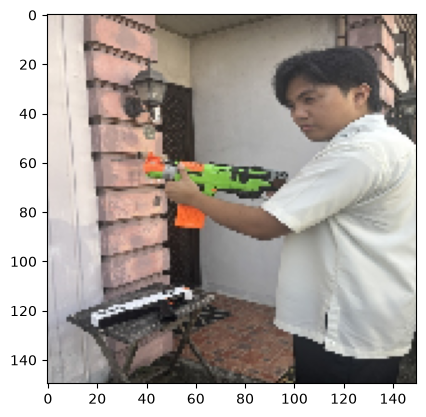

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
[[0.21371603 0.09123418 0.6050746  0.08997512]]
ranged
ALERT: ranged weapon detected, confidence 0.6050746


In [27]:
# load an image for prediction
img = load_img('my_photos_test/ranged_test2.jpg', target_size=(150, 150))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 150, 150, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

# Conclusion

This part (C1) is the **baseline** that every other notebook (C2-C12) is compared against: 3 Conv2D + MaxPooling2D blocks (32, 64, 128 filters), Dense 128, 4-class softmax, 150x150 input, batch size 32, 4 epochs, Adam optimizer. The model was trained on 15,803 images and evaluated on 880 test images across four classes (harmless_object, melee, ranged, student).

**Overall performance:** _(fill in after running: training accuracy, test accuracy, test loss, underfitting or overfitting?)_

**Sample predictions:**

| Class | Typical photos | Our photos | Total |
|---|---|---|---|
| student | /2 | /2 | /4 |
| harmless_object | /2 | /2 | /4 |
| melee | /2 | /2 | /4 |
| ranged | /2 | /2 | /4 |
| All | /8 | /8 | /16 |

**Implication for the alert system:** _(fill in)_

**Limitations:** _(fill in)_

**Recommendations:** _(fill in)_